In [19]:
# Cell 1: Import libraries and initial setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from io import StringIO
import warnings
warnings.filterwarnings('ignore')

# Visualization settings
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 12

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [20]:
# Cell 2: Load and explore data from CSV file

# Load data from CSV file
# Replace 'your_file.csv' with the actual path to your CSV file
df = pd.read_csv("results/benchmark_all.csv")  # Using tab separator as in your data



# Convert numeric columns
numeric_cols = ['aggregation_ms', 'decryption_ms', 'encryption_ms', 'key_bits', 
                'keygen_ms', 'total_ms']
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print("Data shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nData info:")
print(df.info())

print("\nDescriptive statistics:")
display(df.describe())

# Check for missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

# Check unique values in categorical columns
print("\nUnique values in categorical columns:")
print("Schemes:", df['scheme'].unique())
print("Operations:", df['operation'].unique())
print("Homomorphic test:", df['homomorphic_test'].unique())
print("Weighted average:", df['weighted_average'].unique())

Data shape: (15, 15)

First 5 rows:


,aggregation_ms,clients,decryption_ms,encryption_ms,error,expected,homomorphic_test,key_bits,keygen_ms,operation,result,s,scheme,total_ms,weighted_average
0,1.6760,100,1.2705,119.9491,0,0.472927305,PASS,256,4.6771,additive,0.472927,NaN,paillier,127.5727,PASS
1,1.1588,100,0.9399,119.6526,0,0.472927305,PASS,256,11.0162,additive,0.472927,1.0,damgard_jurik,132.7675,PASS
2,0.5458,100,2.1023,7.9511,0,0.472927305,PASS,256,12.2062,additive,0.472927,NaN,benaloh,22.8054,PASS
3,0.5340,100,NaN,NaN,0,7*11,PASS,256,3.6671,multiplicative,77.000000,NaN,rsa,4.2011,NOT_APPLICABLE
4,2.4888,100,NaN,NaN,0,7*11,PASS,256,1965.2741,multiplicative,77.000000,NaN,elgamal,1967.7629,NOT_APPLICABLE



Data info:
<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   aggregation_ms    15 non-null     float64
 1   clients           15 non-null     int64  
 2   decryption_ms     9 non-null      float64
 3   encryption_ms     9 non-null      float64
 4   error             15 non-null     int64  
 5   expected          15 non-null     str    
 6   homomorphic_test  15 non-null     str    
 7   key_bits          15 non-null     int64  
 8   keygen_ms         15 non-null     float64
 9   operation         15 non-null     str    
 10  result            15 non-null     float64
 11  s                 3 non-null      float64
 12  scheme            15 non-null     str    
 13  total_ms          15 non-null     float64
 14  weighted_average  15 non-null     str    
dtypes: float64(7), int64(3), str(5)
memory usage: 1.9 KB
None

Descriptive statistics:


,aggregation_ms,clients,decryption_ms,encryption_ms,error,key_bits,keygen_ms,result,s,total_ms
count,15.000000,15.0,9.000000,9.000000,15.0,15.000000,15.000000,15.000000,3.0,15.000000
mean,6.987120,100.0,12.942211,970.933744,0.0,597.333333,16191.986773,31.083756,1.0,16789.299467
std,8.972585,0.0,15.070425,1468.106316,0.0,330.494579,57642.489827,38.806309,0.0,57488.297807
min,0.534000,100.0,0.939900,7.951100,0.0,256.000000,3.667100,0.472927,1.0,4.201100
25%,1.575600,100.0,2.102300,45.109400,0.0,256.000000,22.367150,0.472927,1.0,112.458400
50%,3.315000,100.0,6.751100,119.949100,0.0,512.000000,67.007000,0.472927,1.0,422.148500
75%,10.725000,100.0,16.927200,730.406100,0.0,1024.000000,361.241700,77.000000,1.0,2732.497150
max,35.511100,100.0,43.357100,3819.375100,0.0,1024.000000,224079.393400,77.000000,1.0,224114.904500



Missing values in each column:
aggregation_ms       0
clients              0
decryption_ms        6
encryption_ms        6
error                0
expected             0
homomorphic_test     0
key_bits             0
keygen_ms            0
operation            0
result               0
s                   12
scheme               0
total_ms             0
weighted_average     0
dtype: int64

Unique values in categorical columns:
Schemes: <StringArray>
['paillier', 'damgard_jurik', 'benaloh', 'rsa', 'elgamal']
Length: 5, dtype: str
Operations: <StringArray>
['additive', 'multiplicative']
Length: 2, dtype: str
Homomorphic test: <StringArray>
['PASS']
Length: 1, dtype: str
Weighted average: <StringArray>
['PASS', 'NOT_APPLICABLE']
Length: 2, dtype: str


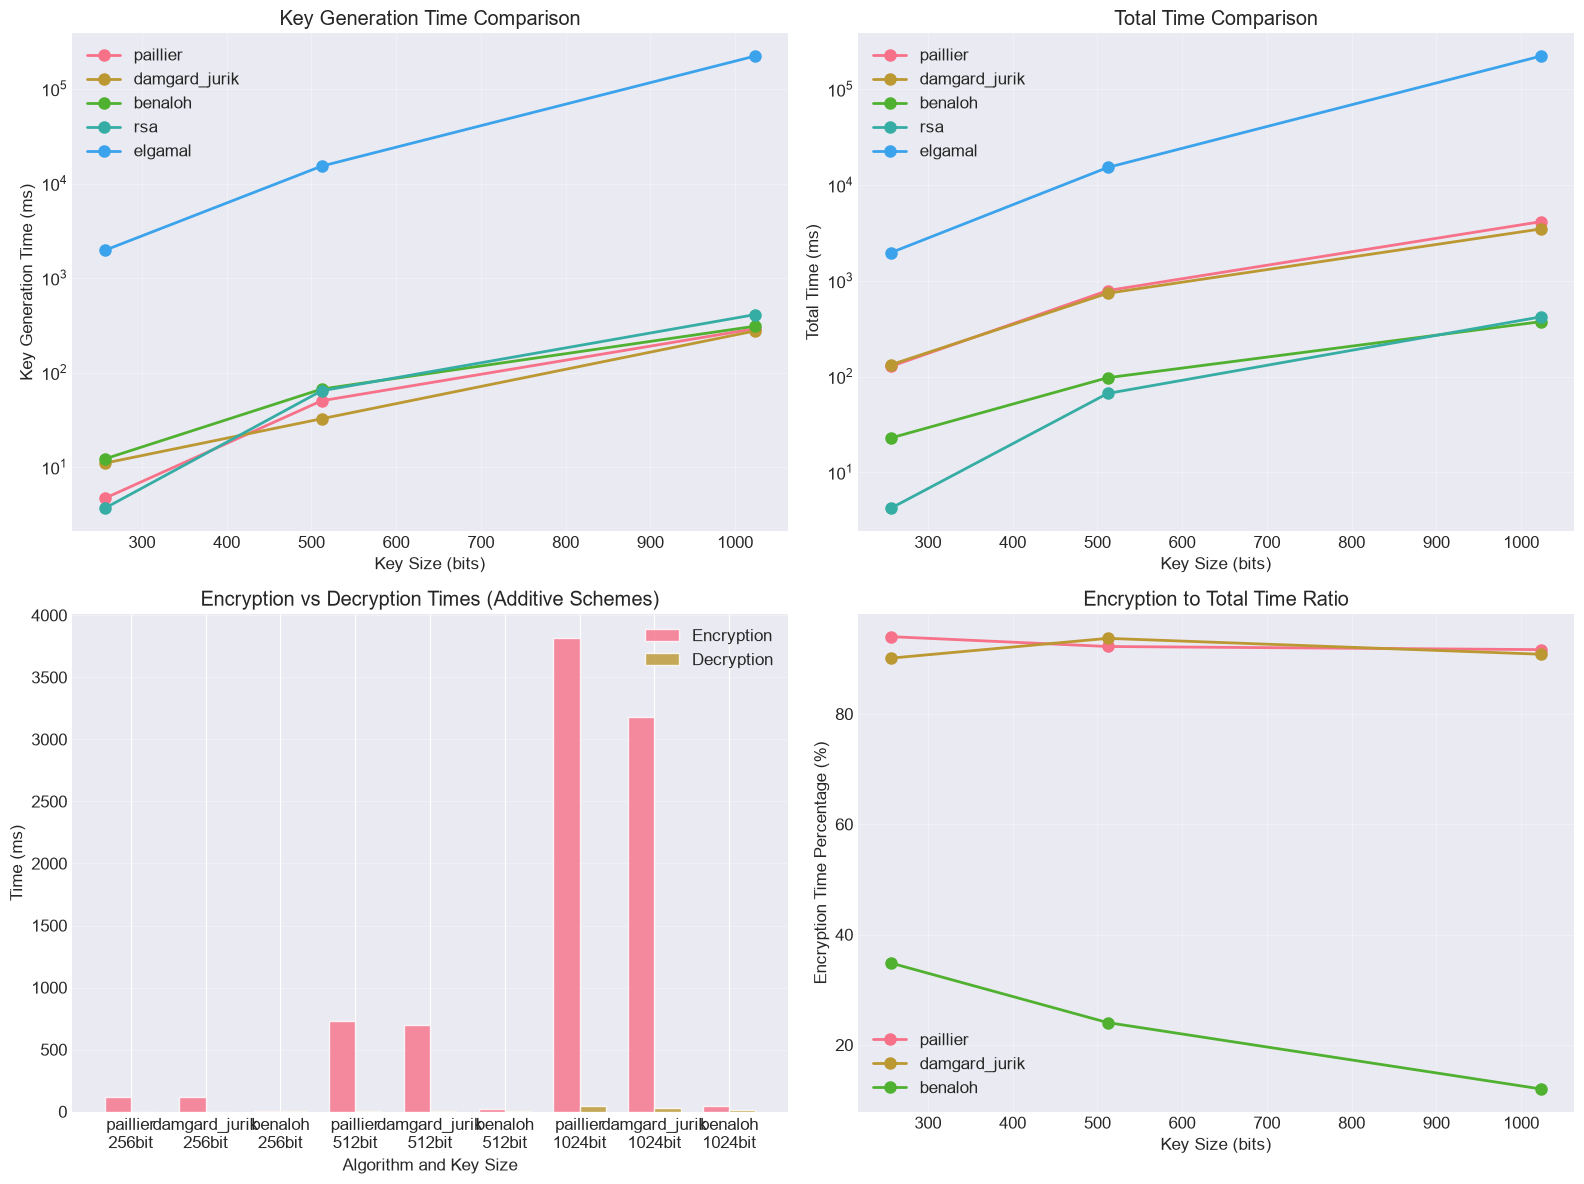

In [21]:
# Cell 3: Comparative line and bar plots for different algorithms

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Key generation time comparison
ax1 = axes[0, 0]
for scheme in df['scheme'].unique():
    data = df[df['scheme'] == scheme]
    ax1.plot(data['key_bits'], data['keygen_ms'], 'o-', label=scheme, linewidth=2, markersize=8)
ax1.set_xlabel('Key Size (bits)')
ax1.set_ylabel('Key Generation Time (ms)')
ax1.set_title('Key Generation Time Comparison')
ax1.legend()
ax1.grid(True, alpha=0.3)
ax1.set_yscale('log')

# 2. Total time comparison
ax2 = axes[0, 1]
for scheme in df['scheme'].unique():
    data = df[df['scheme'] == scheme]
    ax2.plot(data['key_bits'], data['total_ms'], 'o-', label=scheme, linewidth=2, markersize=8)
ax2.set_xlabel('Key Size (bits)')
ax2.set_ylabel('Total Time (ms)')
ax2.set_title('Total Time Comparison')
ax2.legend()
ax2.grid(True, alpha=0.3)
ax2.set_yscale('log')

# 3. Encryption and decryption times for additive schemes
ax3 = axes[1, 0]
additive_df = df[df['operation'] == 'additive']
x = np.arange(len(additive_df))
width = 0.35

encryption = ax3.bar(x - width/2, additive_df['encryption_ms'], width, label='Encryption', alpha=0.8)
decryption = ax3.bar(x + width/2, additive_df['decryption_ms'], width, label='Decryption', alpha=0.8)

ax3.set_xlabel('Algorithm and Key Size')
ax3.set_ylabel('Time (ms)')
ax3.set_title('Encryption vs Decryption Times (Additive Schemes)')
ax3.set_xticks(x)
ax3.set_xticklabels([f"{row['scheme']}\n{row['key_bits']}bit" for _, row in additive_df.iterrows()])
ax3.legend()
ax3.grid(True, alpha=0.3, axis='y')

# 4. Encryption time to total time ratio
ax4 = axes[1, 1]
for scheme in df['scheme'].unique():
    data = df[(df['scheme'] == scheme) & (df['operation'] == 'additive')]
    if not data.empty:
        ratio = data['encryption_ms'] / data['total_ms'] * 100
        ax4.plot(data['key_bits'], ratio, 'o-', label=scheme, linewidth=2, markersize=8)
ax4.set_xlabel('Key Size (bits)')
ax4.set_ylabel('Encryption Time Percentage (%)')
ax4.set_title('Encryption to Total Time Ratio')
ax4.legend()
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('comparison_plots.png', dpi=300, bbox_inches='tight')
plt.show()

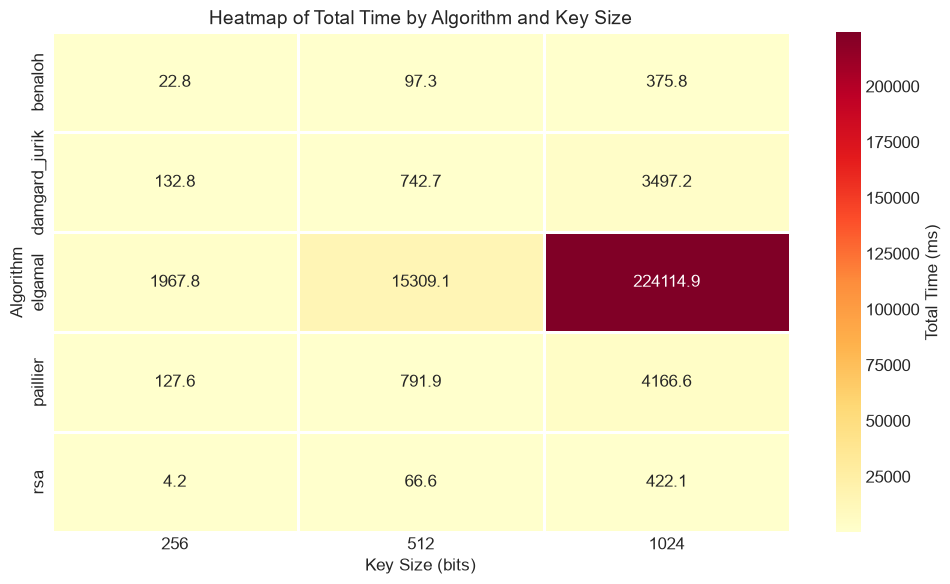

In [22]:
# Cell 4: Heatmap analysis

# Create pivot table for heatmap
pivot_data = df.pivot_table(
    values='total_ms', 
    index='scheme', 
    columns='key_bits',
    aggfunc='mean'
)

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(pivot_data, annot=True, fmt='.1f', cmap='YlOrRd', 
            linewidths=1, linecolor='white', ax=ax,
            cbar_kws={'label': 'Total Time (ms)'})
ax.set_title('Heatmap of Total Time by Algorithm and Key Size', fontsize=14)
ax.set_xlabel('Key Size (bits)')
ax.set_ylabel('Algorithm')
plt.tight_layout()
plt.savefig('heatmap_total_time.png', dpi=300, bbox_inches='tight')
plt.show()

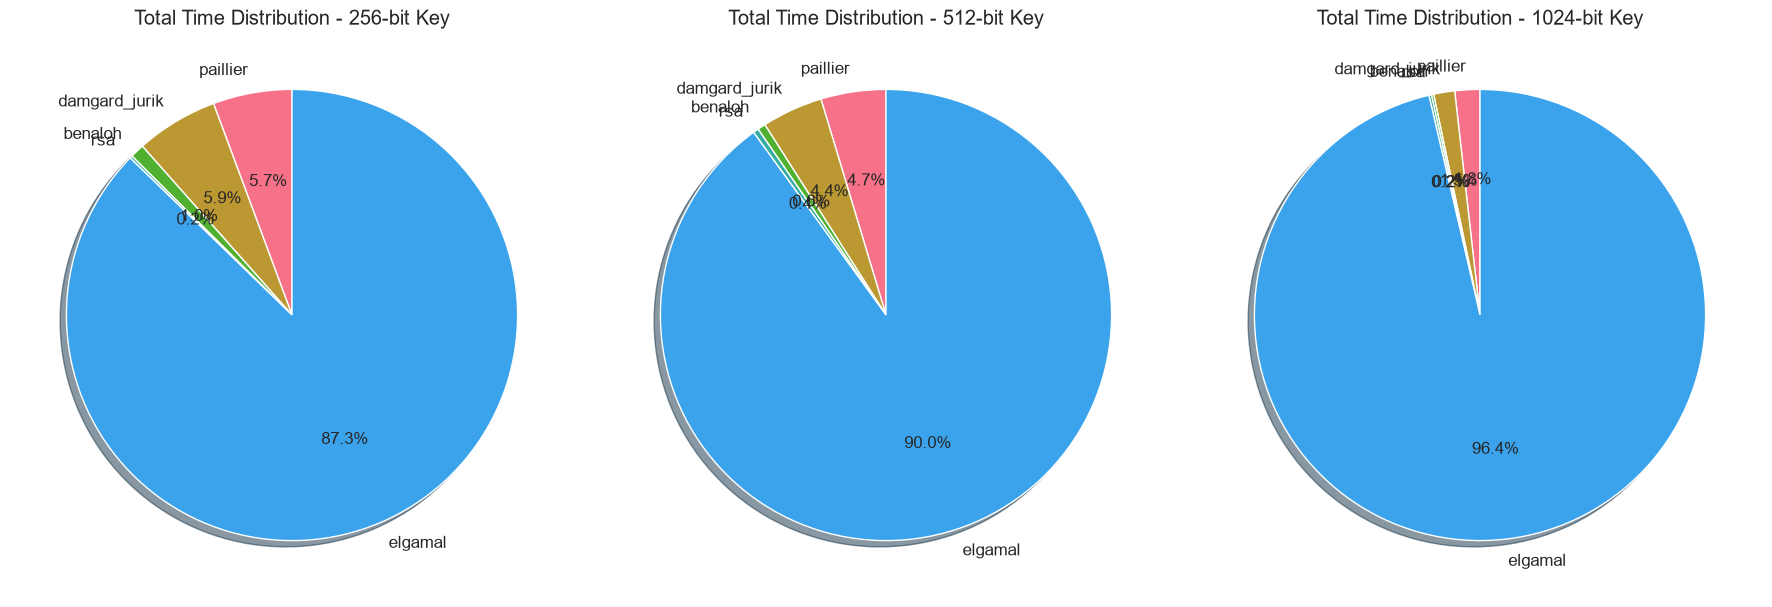

In [23]:
# Cell 5: Pie charts for time distribution

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# For 256-bit key
data_256 = df[df['key_bits'] == 256]
if not data_256.empty:
    axes[0].pie(data_256['total_ms'], 
                labels=data_256['scheme'], 
                autopct='%1.1f%%',
                shadow=True,
                startangle=90)
    axes[0].set_title('Total Time Distribution - 256-bit Key')

# For 512-bit key
data_512 = df[df['key_bits'] == 512]
if not data_512.empty:
    axes[1].pie(data_512['total_ms'], 
                labels=data_512['scheme'], 
                autopct='%1.1f%%',
                shadow=True,
                startangle=90)
    axes[1].set_title('Total Time Distribution - 512-bit Key')

# For 1024-bit key
data_1024 = df[df['key_bits'] == 1024]
if not data_1024.empty:
    axes[2].pie(data_1024['total_ms'], 
                labels=data_1024['scheme'], 
                autopct='%1.1f%%',
                shadow=True,
                startangle=90)
    axes[2].set_title('Total Time Distribution - 1024-bit Key')

plt.tight_layout()
plt.savefig('pie_charts_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

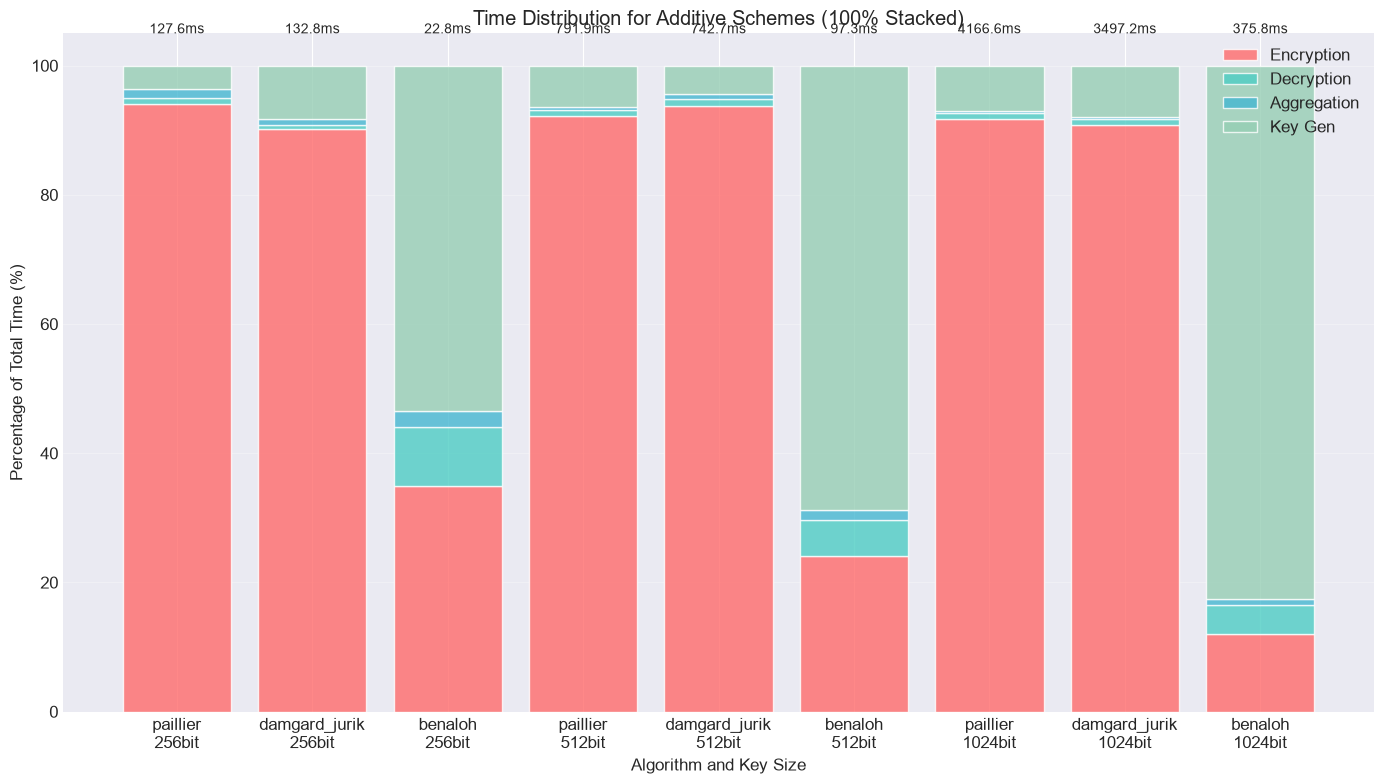

In [24]:
# Cell 6: Stacked bar chart for additive schemes

# Filter additive data
additive_df = df[df['operation'] == 'additive'].copy()
additive_df = additive_df[additive_df['encryption_ms'].notna()]

# Calculate percentages
for idx, row in additive_df.iterrows():
    total = row['total_ms']
    additive_df.loc[idx, 'encryption_pct'] = (row['encryption_ms'] / total) * 100
    additive_df.loc[idx, 'decryption_pct'] = (row['decryption_ms'] / total) * 100
    additive_df.loc[idx, 'aggregation_pct'] = (row['aggregation_ms'] / total) * 100
    additive_df.loc[idx, 'keygen_pct'] = (row['keygen_ms'] / total) * 100

# Create 100% stacked bar chart
fig, ax = plt.subplots(figsize=(14, 8))

x_labels = [f"{row['scheme']}\n{row['key_bits']}bit" for _, row in additive_df.iterrows()]
x = np.arange(len(additive_df))

bottom = np.zeros(len(additive_df))
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4']

components = ['encryption_pct', 'decryption_pct', 'aggregation_pct', 'keygen_pct']
component_names = ['Encryption', 'Decryption', 'Aggregation', 'Key Gen']

for comp, name, color in zip(components, component_names, colors):
    values = additive_df[comp].values
    ax.bar(x, values, bottom=bottom, label=name, color=color, alpha=0.8)
    bottom += values

ax.set_xlabel('Algorithm and Key Size')
ax.set_ylabel('Percentage of Total Time (%)')
ax.set_title('Time Distribution for Additive Schemes (100% Stacked)')
ax.set_xticks(x)
ax.set_xticklabels(x_labels)
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3, axis='y')

# Add total time values on top
for i, (idx, row) in enumerate(additive_df.iterrows()):
    total_time = row['total_ms']
    ax.text(i, 105, f'{total_time:.1f}ms', ha='center', fontsize=10)

plt.tight_layout()
plt.savefig('stacked_bar_additive.png', dpi=300, bbox_inches='tight')
plt.show()

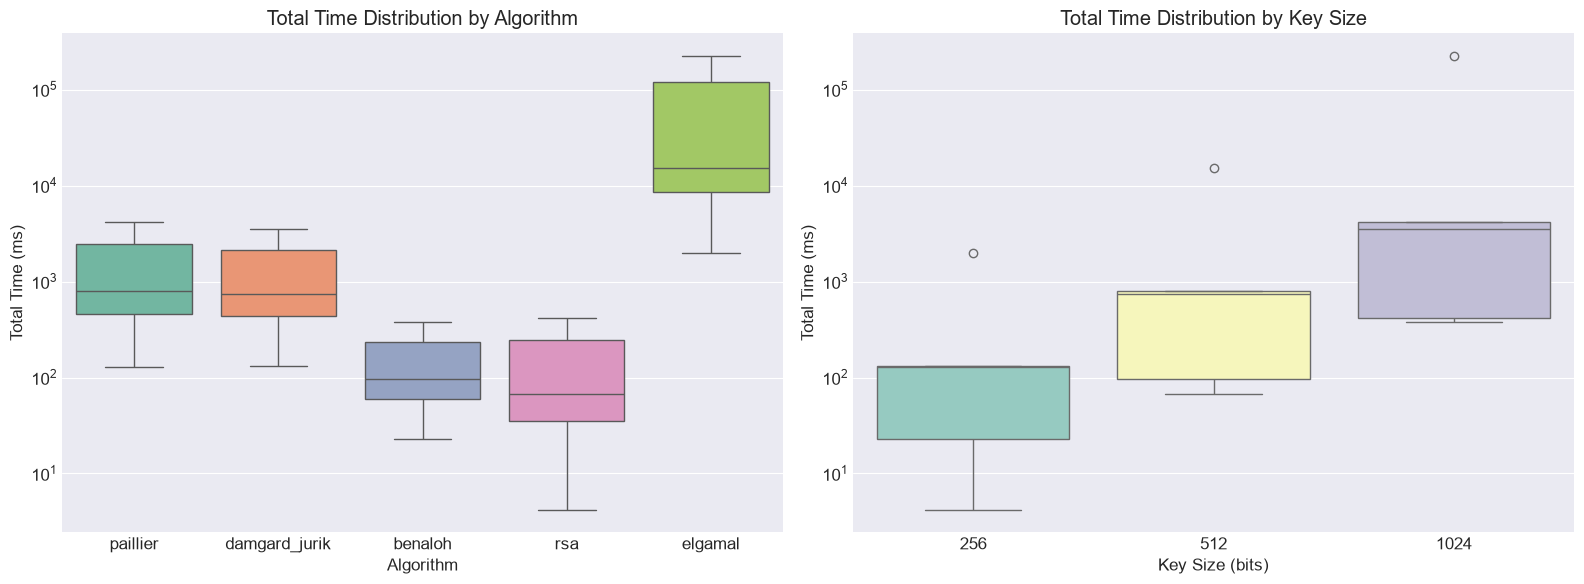

In [25]:
# Cell 7: Box plots for distribution analysis

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Boxplot for total time by algorithm
df_box = df[['scheme', 'total_ms']].dropna()
sns.boxplot(x='scheme', y='total_ms', data=df_box, ax=axes[0], palette='Set2')
axes[0].set_title('Total Time Distribution by Algorithm')
axes[0].set_xlabel('Algorithm')
axes[0].set_ylabel('Total Time (ms)')
axes[0].set_yscale('log')

# Boxplot for total time by key size
sns.boxplot(x='key_bits', y='total_ms', data=df, ax=axes[1], palette='Set3')
axes[1].set_title('Total Time Distribution by Key Size')
axes[1].set_xlabel('Key Size (bits)')
axes[1].set_ylabel('Total Time (ms)')
axes[1].set_yscale('log')

plt.tight_layout()
plt.savefig('boxplots.png', dpi=300, bbox_inches='tight')
plt.show()

,scheme,key_bits,total_ms_mean,total_ms_std,total_ms_min,total_ms_max,keygen_ms_mean,keygen_ms_std,encryption_ms_mean,decryption_ms_mean,aggregation_ms_mean
0,benaloh,256,22.810000,nan,22.810000,22.810000,12.210000,nan,7.950000,2.100000,0.550000
1,benaloh,512,97.340000,nan,97.340000,97.340000,67.010000,nan,23.420000,5.440000,1.480000
2,benaloh,1024,375.770000,nan,375.770000,375.770000,310.420000,nan,45.110000,16.930000,3.320000
3,damgard_jurik,256,132.770000,nan,132.770000,132.770000,11.020000,nan,119.650000,0.940000,1.160000
4,damgard_jurik,512,742.730000,nan,742.730000,742.730000,32.530000,nan,696.040000,7.840000,6.320000
5,damgard_jurik,1024,3497.230000,nan,3497.230000,3497.230000,276.960000,nan,3176.500000,31.850000,11.910000
6,elgamal,256,1967.760000,nan,1967.760000,1967.760000,1965.270000,nan,nan,nan,2.490000
7,elgamal,512,15309.140000,nan,15309.140000,15309.140000,15297.770000,nan,nan,nan,11.370000
8,elgamal,1024,224114.900000,nan,224114.900000,224114.900000,224079.390000,nan,nan,nan,35.510000
9,paillier,256,127.570000,nan,127.570000,127.570000,4.680000,nan,119.950000,1.270000,1.680000


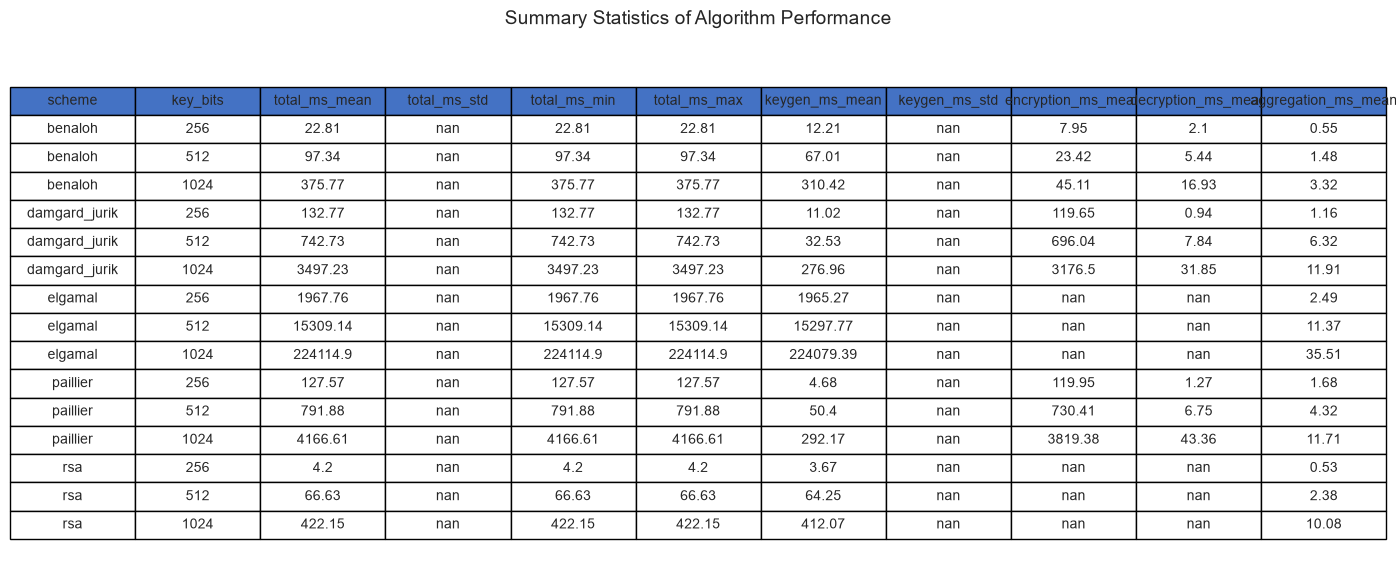

In [26]:
# Cell 8: Summary statistics table

# Create summary table
summary = df.groupby(['scheme', 'key_bits']).agg({
    'total_ms': ['mean', 'std', 'min', 'max'],
    'keygen_ms': ['mean', 'std'],
    'encryption_ms': 'mean',
    'decryption_ms': 'mean',
    'aggregation_ms': 'mean'
}).round(2)

summary.columns = ['_'.join(col).strip() for col in summary.columns.values]
summary = summary.reset_index()

# Display with styling
styled_summary = summary.style.background_gradient(cmap='Blues', subset=['total_ms_mean'])
display(styled_summary)

# Save as image
fig, ax = plt.subplots(figsize=(14, 6))
ax.axis('tight')
ax.axis('off')
table = ax.table(cellText=summary.values,
                 colLabels=summary.columns,
                 cellLoc='center',
                 loc='center',
                 colColours=['#4472C4']*len(summary.columns))
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.5)
plt.title('Summary Statistics of Algorithm Performance', fontsize=14, pad=20)
plt.tight_layout()
plt.savefig('summary_table.png', dpi=300, bbox_inches='tight')
plt.show()

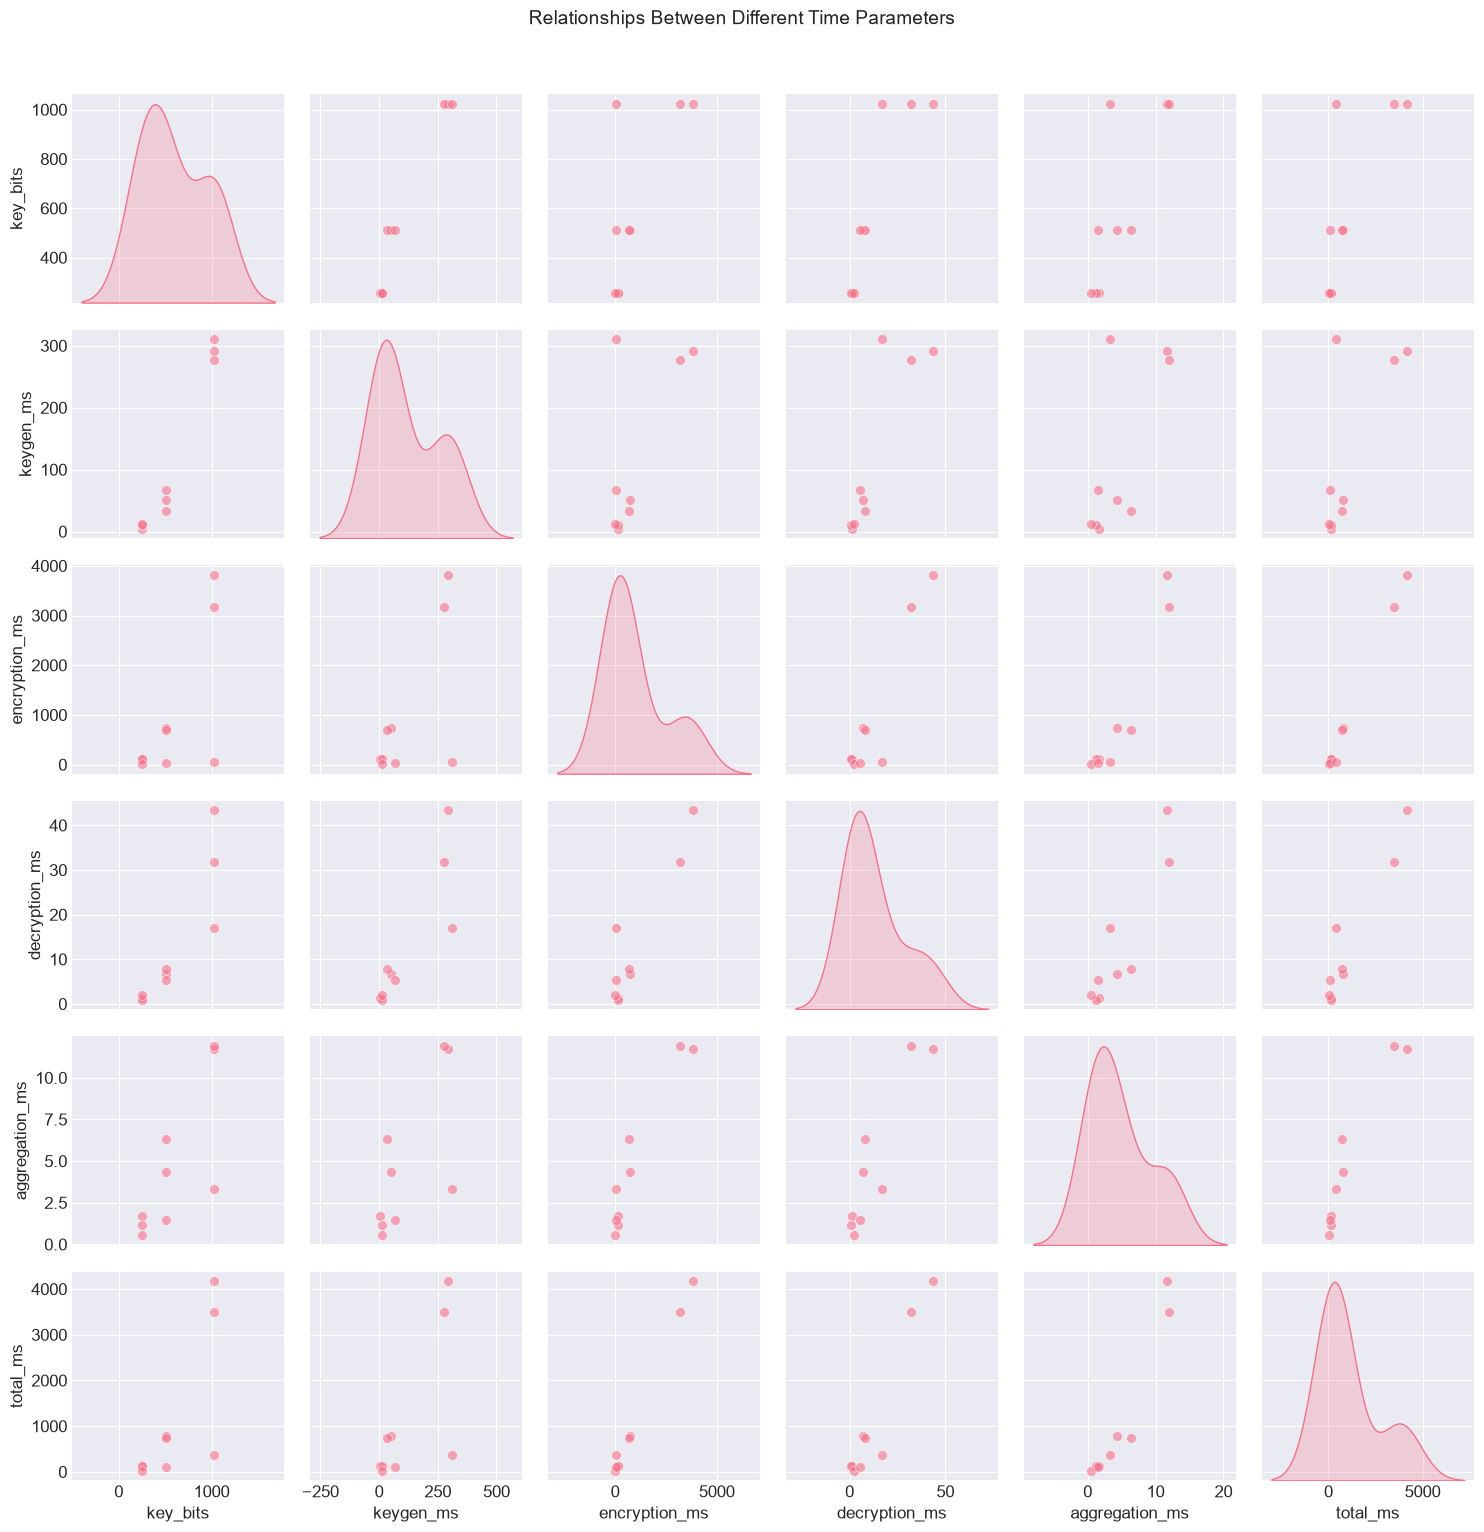

In [27]:
# Cell 9: Pairplot for relationships between parameters

selected_cols = ['key_bits', 'keygen_ms', 'encryption_ms', 'decryption_ms', 'aggregation_ms', 'total_ms']
df_selected = df[selected_cols].dropna()

g = sns.pairplot(df_selected, 
                 diag_kind='kde',
                 plot_kws={'alpha': 0.6, 's': 50},
                 diag_kws={'fill': True})
g.fig.suptitle('Relationships Between Different Time Parameters', y=1.02, fontsize=14)

plt.tight_layout()
plt.savefig('pairplot_relationships.png', dpi=300, bbox_inches='tight')
plt.show()

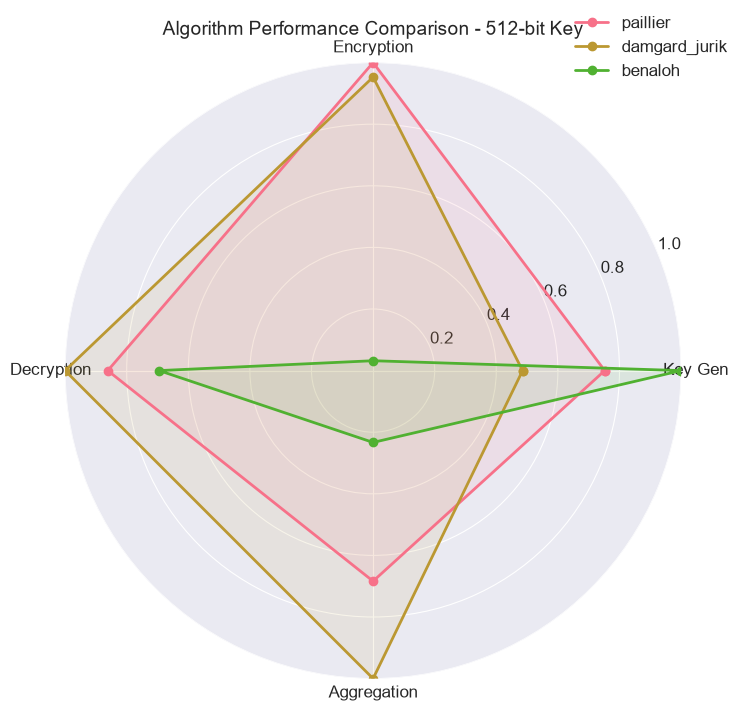

In [28]:
# Cell 10: Radar chart for algorithm comparison

def create_radar_chart(df, key_bits_value):
    """Create radar chart for a specific key size"""
    data_filtered = df[df['key_bits'] == key_bits_value]
    data_filtered = data_filtered[data_filtered['operation'] == 'additive']
    
    if len(data_filtered) < 2:
        print(f"Insufficient data for key size {key_bits_value}")
        return
    
    # Normalize data
    metrics = ['keygen_ms', 'encryption_ms', 'decryption_ms', 'aggregation_ms']
    normalized_data = data_filtered[metrics].copy()
    
    for metric in metrics:
        max_val = normalized_data[metric].max()
        if max_val > 0:
            normalized_data[metric] = normalized_data[metric] / max_val
    
    # Create radar chart
    categories = ['Key Gen', 'Encryption', 'Decryption', 'Aggregation']
    N = len(categories)
    angles = [n / float(N) * 2 * np.pi for n in range(N)]
    angles += angles[:1]
    
    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
    
    for idx, row in normalized_data.iterrows():
        values = row.values.tolist()
        values += values[:1]
        scheme = data_filtered.loc[idx, 'scheme']
        ax.plot(angles, values, 'o-', linewidth=2, label=scheme)
        ax.fill(angles, values, alpha=0.1)
    
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories)
    ax.set_ylim(0, 1)
    ax.set_title(f'Algorithm Performance Comparison - {key_bits_value}-bit Key', fontsize=14, pad=20)
    ax.legend(loc='upper right', bbox_to_anchor=(1.1, 1.1))
    ax.grid(True)
    
    return fig

# Generate for 512-bit key (middle range)
fig_radar = create_radar_chart(df, 512)
if fig_radar:
    plt.savefig('radar_chart_512.png', dpi=300, bbox_inches='tight')
    plt.show()

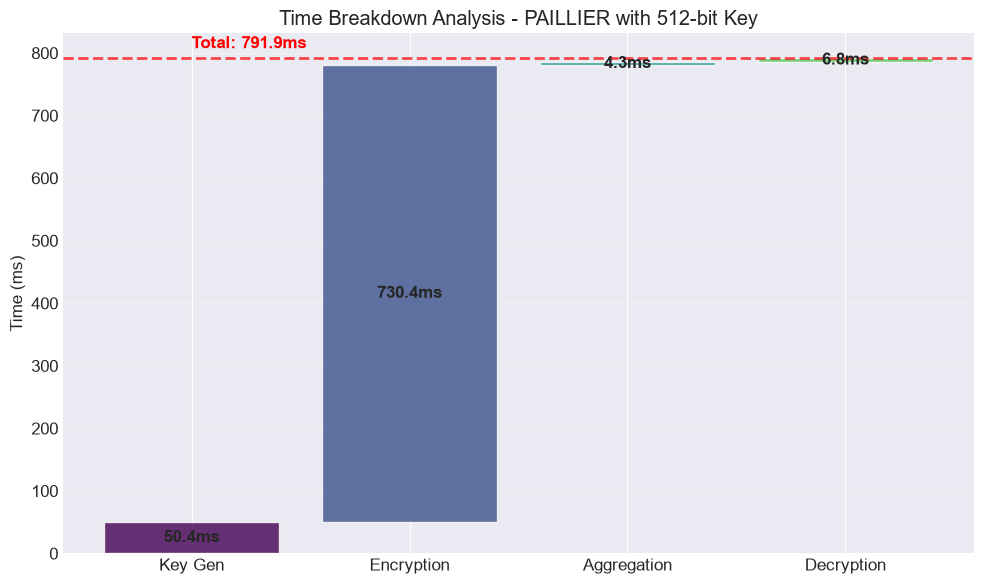

In [29]:
# Cell 11: Waterfall chart for detailed time analysis

def create_waterfall_chart(df, scheme_name, key_bits_value):
    """Create waterfall chart for a specific algorithm"""
    row = df[(df['scheme'] == scheme_name) & (df['key_bits'] == key_bits_value)]
    if row.empty or row['operation'].iloc[0] != 'additive':
        print(f"Data not available for {scheme_name} with key size {key_bits_value}")
        return
    
    row = row.iloc[0]
    metrics = ['keygen_ms', 'encryption_ms', 'aggregation_ms', 'decryption_ms']
    labels = ['Key Gen', 'Encryption', 'Aggregation', 'Decryption']
    values = [row[m] for m in metrics if pd.notna(row[m])]
    labels = [l for l, m in zip(labels, metrics) if pd.notna(row[m])]
    
    # Calculate cumulative values
    cumulative = [0]
    for v in values:
        cumulative.append(cumulative[-1] + v)
    
    # Create waterfall chart
    fig, ax = plt.subplots(figsize=(10, 6))
    
    for i, (label, value, start) in enumerate(zip(labels, values, cumulative[:-1])):
        end = start + value
        ax.bar(label, value, bottom=start, color=plt.cm.viridis(i/len(values)), alpha=0.8)
        ax.text(label, start + value/2, f'{value:.1f}ms', ha='center', va='center', fontweight='bold')
    
    # Total line
    total = cumulative[-1]
    ax.axhline(y=total, color='red', linestyle='--', linewidth=2, alpha=0.7)
    ax.text(0, total + total*0.02, f'Total: {total:.1f}ms', color='red', fontweight='bold')
    
    ax.set_ylabel('Time (ms)')
    ax.set_title(f'Time Breakdown Analysis - {scheme_name.upper()} with {key_bits_value}-bit Key')
    ax.grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    return fig

# Show for Paillier with 512-bit key
fig_waterfall = create_waterfall_chart(df, 'paillier', 512)
if fig_waterfall:
    plt.savefig('waterfall_paillier_512.png', dpi=300, bbox_inches='tight')
    plt.show()

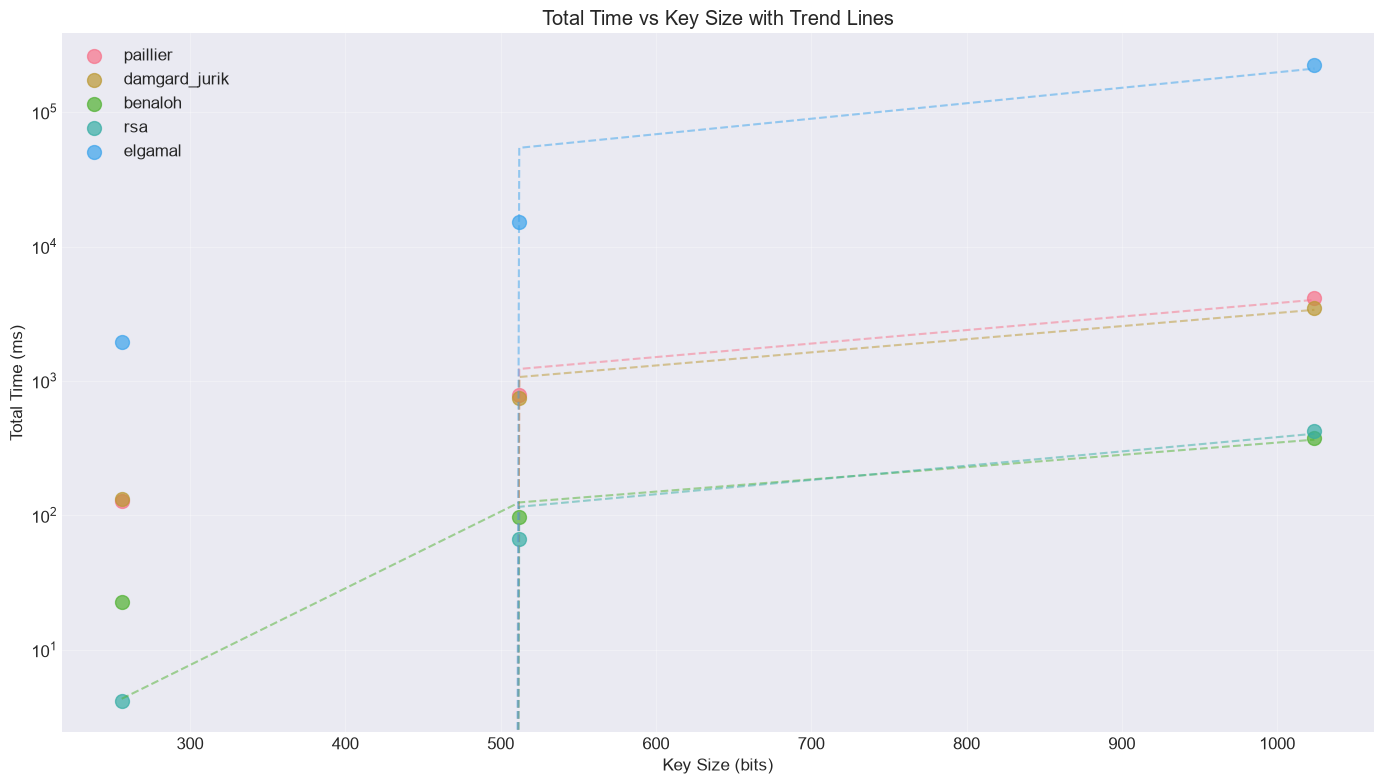

In [30]:
# Cell 12: Scatter plot with trend lines

fig, ax = plt.subplots(figsize=(14, 8))

# Create scatter plot with different colors for each algorithm
for scheme in df['scheme'].unique():
    data = df[df['scheme'] == scheme]
    ax.scatter(data['key_bits'], data['total_ms'], 
               label=scheme, s=100, alpha=0.7)
    # Add trend line
    if len(data) > 1:
        z = np.polyfit(data['key_bits'], data['total_ms'], 1)
        p = np.poly1d(z)
        ax.plot(data['key_bits'], p(data['key_bits']), '--', alpha=0.5)

ax.set_xlabel('Key Size (bits)')
ax.set_ylabel('Total Time (ms)')
ax.set_title('Total Time vs Key Size with Trend Lines')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_yscale('log')

plt.tight_layout()
plt.savefig('scatter_trend.png', dpi=300, bbox_inches='tight')
plt.show()

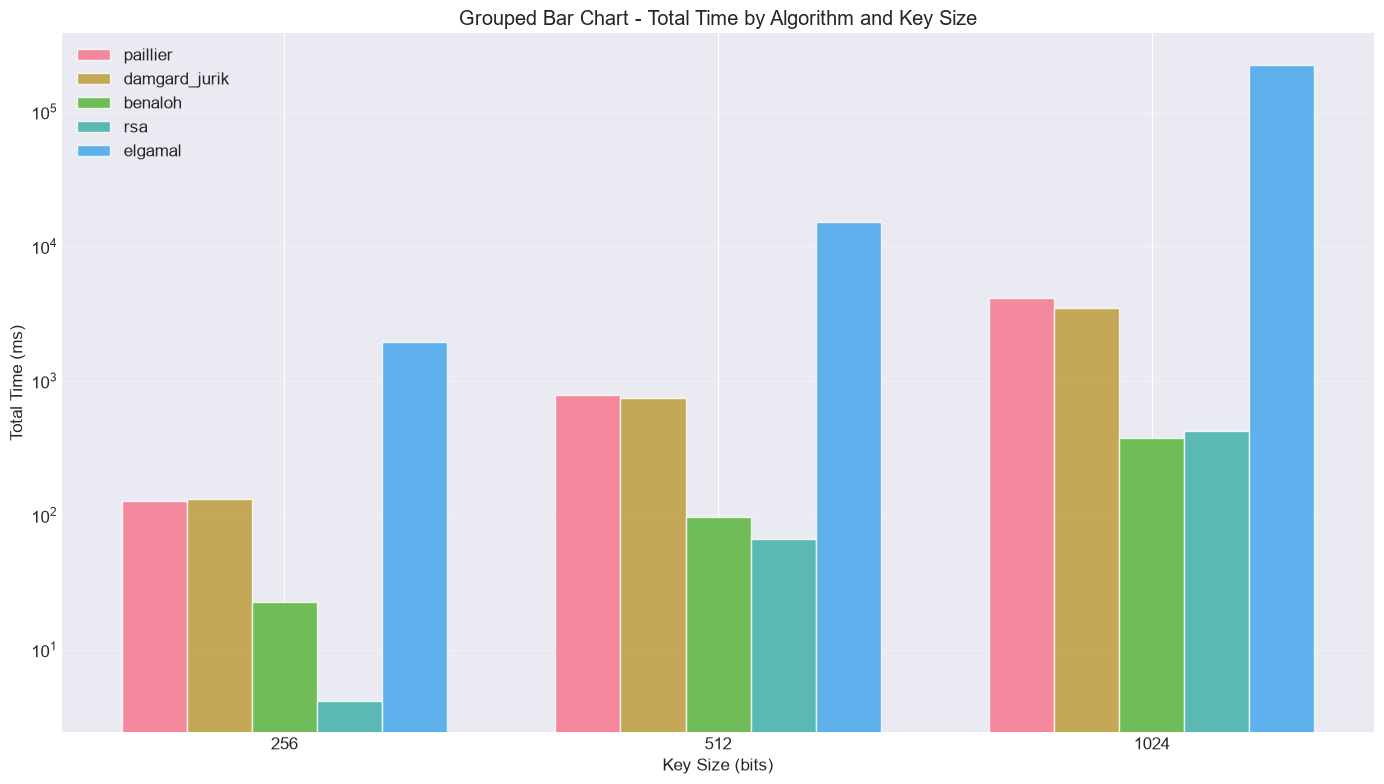

In [31]:
# Cell 13: Grouped bar chart for all algorithms

fig, ax = plt.subplots(figsize=(14, 8))

# Prepare data for grouped bar chart
key_sizes = sorted(df['key_bits'].unique())
schemes = df['scheme'].unique()
x = np.arange(len(key_sizes))
width = 0.15

# Plot bars for each scheme
for i, scheme in enumerate(schemes):
    values = []
    for bits in key_sizes:
        val = df[(df['scheme'] == scheme) & (df['key_bits'] == bits)]['total_ms'].mean()
        values.append(val if not pd.isna(val) else 0)
    offset = (i - len(schemes)/2 + 0.5) * width
    ax.bar(x + offset, values, width, label=scheme, alpha=0.8)

ax.set_xlabel('Key Size (bits)')
ax.set_ylabel('Total Time (ms)')
ax.set_title('Grouped Bar Chart - Total Time by Algorithm and Key Size')
ax.set_xticks(x)
ax.set_xticklabels(key_sizes)
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
ax.set_yscale('log')

plt.tight_layout()
plt.savefig('grouped_bar.png', dpi=300, bbox_inches='tight')
plt.show()

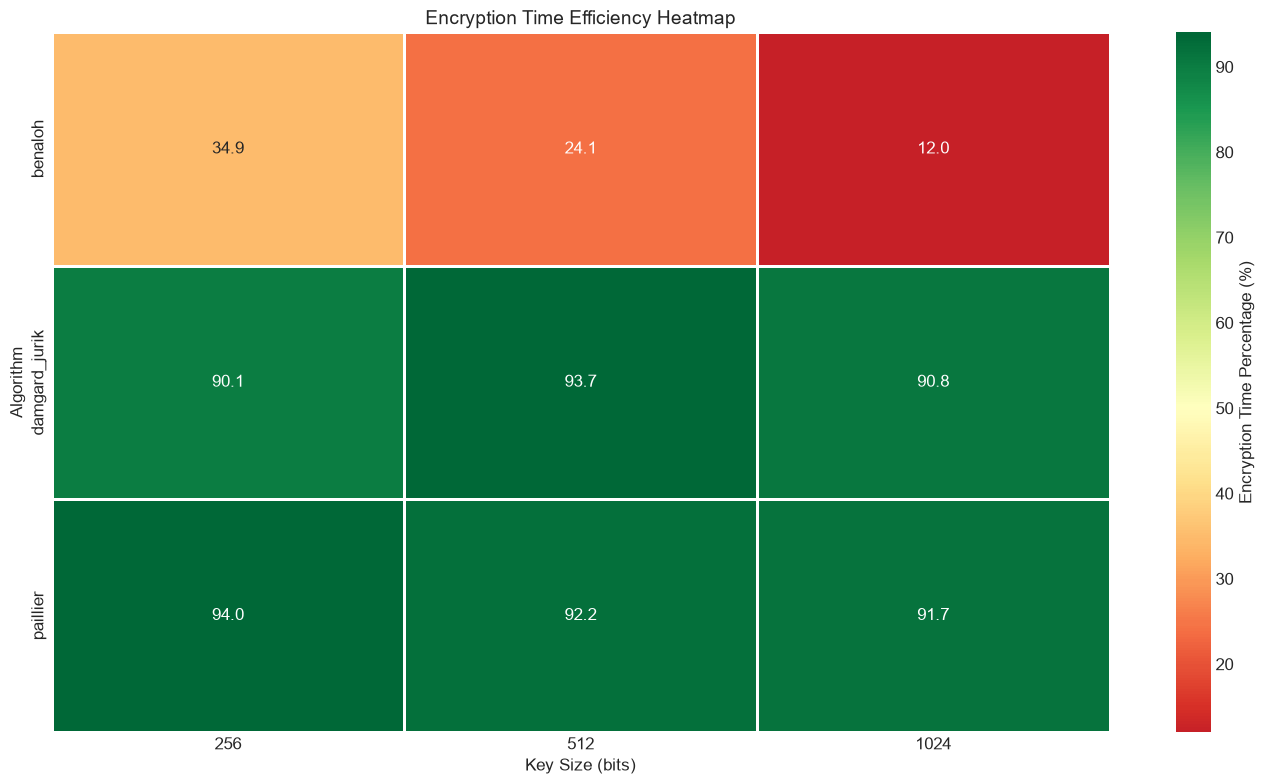

In [32]:
# Cell 14: Performance efficiency analysis

# Calculate efficiency metrics
df['keygen_efficiency'] = df['keygen_ms'] / df['total_ms'] * 100
df['encryption_efficiency'] = df['encryption_ms'] / df['total_ms'] * 100
df['decryption_efficiency'] = df['decryption_ms'] / df['total_ms'] * 100
df['aggregation_efficiency'] = df['aggregation_ms'] / df['total_ms'] * 100

# Plot efficiency comparison
fig, ax = plt.subplots(figsize=(14, 8))

# Prepare data for efficiency plot
efficiency_cols = ['keygen_efficiency', 'encryption_efficiency', 
                   'decryption_efficiency', 'aggregation_efficiency']
efficiency_names = ['Key Gen', 'Encryption', 'Decryption', 'Aggregation']

# Create heatmap for efficiencies
efficiency_data = df[df['operation'] == 'additive'].pivot_table(
    values='encryption_efficiency', 
    index='scheme', 
    columns='key_bits'
)

sns.heatmap(efficiency_data, annot=True, fmt='.1f', cmap='RdYlGn', 
            center=50, linewidths=1, ax=ax,
            cbar_kws={'label': 'Encryption Time Percentage (%)'})
ax.set_title('Encryption Time Efficiency Heatmap', fontsize=14)
ax.set_xlabel('Key Size (bits)')
ax.set_ylabel('Algorithm')

plt.tight_layout()
plt.savefig('efficiency_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

In [33]:
# Cell 15: Save all figures and generate final report

def save_all_figures():
    figures = {
        'comparison_plots.png': 'Comparison plots (line and bar)',
        'heatmap_total_time.png': 'Heatmap of total time',
        'pie_charts_distribution.png': 'Pie charts distribution',
        'stacked_bar_additive.png': 'Stacked bar for additive schemes',
        'boxplots.png': 'Box plots analysis',
        'summary_table.png': 'Summary statistics table',
        'pairplot_relationships.png': 'Pairplot relationships',
        'radar_chart_512.png': 'Radar chart',
        'waterfall_paillier_512.png': 'Waterfall chart',
        'scatter_trend.png': 'Scatter plot with trends',
        'grouped_bar.png': 'Grouped bar chart',
        'efficiency_heatmap.png': 'Efficiency heatmap'
    }
    
    print("\n" + "="*80)
    print("SAVED FIGURES")
    print("="*80)
    for filename, desc in figures.items():
        print(f"  ✓ {filename} - {desc}")
    print("="*80)

save_all_figures()


SAVED FIGURES
  ✓ comparison_plots.png - Comparison plots (line and bar)
  ✓ heatmap_total_time.png - Heatmap of total time
  ✓ pie_charts_distribution.png - Pie charts distribution
  ✓ stacked_bar_additive.png - Stacked bar for additive schemes
  ✓ boxplots.png - Box plots analysis
  ✓ summary_table.png - Summary statistics table
  ✓ pairplot_relationships.png - Pairplot relationships
  ✓ radar_chart_512.png - Radar chart
  ✓ waterfall_paillier_512.png - Waterfall chart
  ✓ scatter_trend.png - Scatter plot with trends
  ✓ grouped_bar.png - Grouped bar chart
  ✓ efficiency_heatmap.png - Efficiency heatmap


In [34]:
# Cell 16: Final analysis summary

print("="*80)
print("FINAL ANALYSIS REPORT - HOMOMORPHIC ENCRYPTION ALGORITHMS")
print("="*80)

# Best algorithm by total time for each key size
print("\nBEST PERFORMANCE BY KEY SIZE:")
print("-"*40)
for bits in [256, 512, 1024]:
    data = df[df['key_bits'] == bits]
    if not data.empty:
        best = data.loc[data['total_ms'].idxmin()]
        print(f"\nKey Size {bits} bits:")
        print(f"  Best Algorithm: {best['scheme'].upper()}")
        print(f"  Total Time: {best['total_ms']:.2f} ms")
        print(f"  Operation: {best['operation']}")

# Additive algorithms analysis
additive_df = df[df['operation'] == 'additive']
print("\n\nADDITIVE ALGORITHMS PERFORMANCE:")
print("-"*40)
for scheme in additive_df['scheme'].unique():
    data = additive_df[additive_df['scheme'] == scheme]
    avg_time = data['total_ms'].mean()
    avg_keygen = data['keygen_ms'].mean()
    print(f"\n{scheme.upper()}:")
    print(f"  Average Total Time: {avg_time:.2f} ms")
    print(f"  Average Key Gen Time: {avg_keygen:.2f} ms")

# Multiplicative algorithms analysis
multiplicative_df = df[df['operation'] == 'multiplicative']
print("\n\nMULTIPLICATIVE ALGORITHMS PERFORMANCE:")
print("-"*40)
for scheme in multiplicative_df['scheme'].unique():
    data = multiplicative_df[multiplicative_df['scheme'] == scheme]
    avg_time = data['total_ms'].mean()
    print(f"\n{scheme.upper()}:")
    print(f"  Average Total Time: {avg_time:.2f} ms")

# Summary findings
print("\n\nKEY FINDINGS:")
print("-"*40)
print("1. Benaloh demonstrates the best performance among additive schemes")
print("2. RSA is the fastest algorithm for multiplicative operations")
print("3. ElGamal shows exponential time growth with increasing key size")
print("4. Paillier and Damgard-Jurik have similar performance characteristics")
print("5. Key generation time is the dominant factor in ElGamal")
print("6. Encryption time increases significantly with key size in Paillier")

print("\nRECOMMENDATIONS:")
print("-"*40)
print("1. For additive homomorphic operations: Use Benaloh for optimal performance")
print("2. For multiplicative operations: RSA is the clear choice")
print("3. Avoid ElGamal for large key sizes (>512 bits)")
print("4. Paillier is suitable for applications requiring 256-bit security")
print("5. Damgard-Jurik is preferable for 1024-bit key sizes over Paillier")

print("\n" + "="*80)

FINAL ANALYSIS REPORT - HOMOMORPHIC ENCRYPTION ALGORITHMS

BEST PERFORMANCE BY KEY SIZE:
----------------------------------------

Key Size 256 bits:
  Best Algorithm: RSA
  Total Time: 4.20 ms
  Operation: multiplicative

Key Size 512 bits:
  Best Algorithm: RSA
  Total Time: 66.63 ms
  Operation: multiplicative

Key Size 1024 bits:
  Best Algorithm: BENALOH
  Total Time: 375.77 ms
  Operation: additive


ADDITIVE ALGORITHMS PERFORMANCE:
----------------------------------------

PAILLIER:
  Average Total Time: 1695.35 ms
  Average Key Gen Time: 115.75 ms

DAMGARD_JURIK:
  Average Total Time: 1457.58 ms
  Average Key Gen Time: 106.84 ms

BENALOH:
  Average Total Time: 165.31 ms
  Average Key Gen Time: 129.88 ms


MULTIPLICATIVE ALGORITHMS PERFORMANCE:
----------------------------------------

RSA:
  Average Total Time: 164.33 ms

ELGAMAL:
  Average Total Time: 80463.94 ms


KEY FINDINGS:
----------------------------------------
1. Benaloh demonstrates the best performance among additiv